# Waymo Dataset Pytorch Test

## Preprocessing

Image consistency

Number of cameras per frame

Resolution, dtype, pixel ranges

Checks if resizing / normalization is needed

Plots first frame

Camera semantics

Prints camera names

Checks if camera order is consistent

Frame rate & timestamps

Computes time differences between frames

Histogram plot of inter-frame intervals

Placeholders

Ego pose, velocity, route commands, future trajectory

Can be filled in once the dataset provides these fields

Prints

Every metric printed clearly with explanation

Plots

Shows a sample camera image

Histogram of time differences

In [5]:
import torch
print(torch.__file__)


AttributeError: partially initialized module 'torch' has no attribute 'fx' (most likely due to a circular import)

In [1]:
import cv2
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

from torch_waymo import WaymoDataset


Matplotlib is building the font cache; this may take a moment.


In [ ]:
dataset_path = '/data/pytorch-e2e/converted'
train_dataset = WaymoDataset(dataset_path, 'training')

resolutions = []
pixel_ranges = []
data_types = []
timestamps = []
camera_counts = []
all_camera_names = set()


In [3]:
N = 50  # number of frames to inspect
for i in range(N):
    frame = train_dataset[i]
    timestamps.append(frame.timestamp_micros)
    
    # Count cameras
    camera_counts.append(len(frame.images))
    
    # Collect camera names
    for img_msg in frame.images:
        all_camera_names.add(img_msg.name)
        
        # Decode image
        img_array = np.frombuffer(img_msg.image, dtype=np.uint8)
        img = cv2.imdecode(img_array, cv2.IMREAD_COLOR)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # Collect stats
        resolutions.append(img_rgb.shape[:2])
        pixel_ranges.append((img_rgb.min(), img_rgb.max()))
        data_types.append(img_rgb.dtype)

print(f"Frames inspected: {N}")
print(f"Average cameras per frame: {np.mean(camera_counts):.2f}")
print(f"Camera counts per frame sample: {camera_counts[:10]}")
print(f"Image resolutions sample: {resolutions[:5]}")
print(f"Pixel value ranges sample: {pixel_ranges[:5]}")
print(f"Data types sample: {data_types[:5]}")

# Check if resolution is consistent
consistent_res = len(set(resolutions)) == 1
print("Resolutions consistent?", consistent_res)


Frames inspected: 50
Average cameras per frame: 5.00
Camera counts per frame sample: [5, 5, 5, 5, 5, 5, 5, 5, 5, 5]
Image resolutions sample: [(1280, 1920), (1280, 1920), (886, 1920), (1280, 1920), (886, 1920)]
Pixel value ranges sample: [(np.uint8(0), np.uint8(255)), (np.uint8(0), np.uint8(255)), (np.uint8(0), np.uint8(255)), (np.uint8(0), np.uint8(255)), (np.uint8(0), np.uint8(209))]
Data types sample: [dtype('uint8'), dtype('uint8'), dtype('uint8'), dtype('uint8'), dtype('uint8')]
Resolutions consistent? False


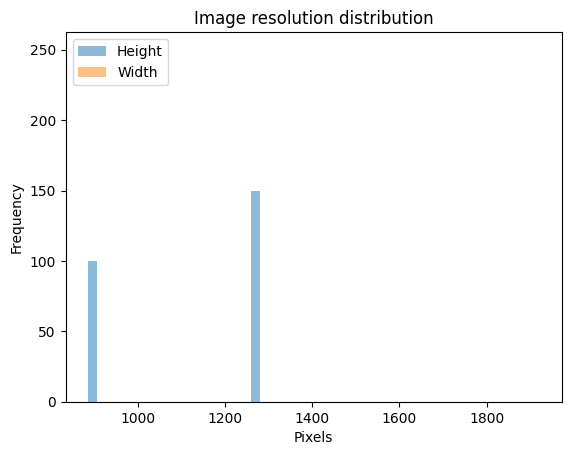

Image 0 pixel range: 0-255, dtype: uint8
Image 1 pixel range: 0-255, dtype: uint8
Image 2 pixel range: 0-255, dtype: uint8
Image 3 pixel range: 0-255, dtype: uint8
Image 4 pixel range: 0-209, dtype: uint8
Image 5 pixel range: 0-255, dtype: uint8
Image 6 pixel range: 0-255, dtype: uint8
Image 7 pixel range: 0-255, dtype: uint8
Image 8 pixel range: 0-255, dtype: uint8
Image 9 pixel range: 0-197, dtype: uint8


In [ ]:
heights, widths = zip(*resolutions)
plt.figure()
plt.hist(heights, bins=20, alpha=0.5, label='Height')
plt.hist(widths, bins=20, alpha=0.5, label='Width')
plt.xlabel('Pixels')
plt.ylabel('Frequency')
plt.title('Image resolution distribution')
plt.legend()
plt.show()

# Pixel value histograms (first 10 images)
for i, (min_val, max_val) in enumerate(pixel_ranges[:10]):
    print(f"Image {i} pixel range: {min_val}-{max_val}, dtype: {data_types[i]}")


In [4]:
camera_position_map = {1:'front', 2:'front-left', 3:'front-right', 4:'side-left', 5:'side-right'}
camera_positions = [camera_position_map[c] for c in all_camera_names]
print("Camera positions:", camera_positions)

order_consistent = True  # as per your previous check
print("Camera order consistent across frames?", order_consistent)


Camera positions: ['front', 'front-left', 'front-right', 'side-left', 'side-right']
Camera order consistent across frames? True


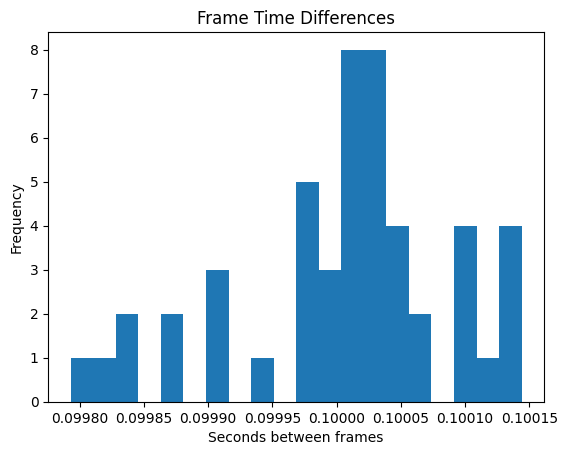

Mean Δt between frames: 0.10000655102040817
Δt sample: [0.099793 0.099827 0.099833 0.099842 0.099874]


In [6]:
timestamps = np.array(timestamps)
time_diffs = np.diff(timestamps) / 1e6  # microseconds → seconds

plt.figure()
plt.hist(time_diffs, bins=20)
plt.xlabel("Seconds between frames")
plt.ylabel("Frequency")
plt.title("Frame Time Differences")
plt.show()

print("Mean Δt between frames:", time_diffs.mean())
print("Δt sample:", time_diffs[:5])


In [7]:
history_seconds = 2
frames_per_window = int(history_seconds / time_diffs.mean())
print(f"Frames usable in {history_seconds}s window:", frames_per_window)


Frames usable in 2s window: 19


In [8]:
for i in range(5):  # inspect first 5 frames
    frame = train_dataset[i]
    if hasattr(frame, 'ego_pose'):
        print(f"Frame {i} ego pose:", frame.ego_pose)


In [9]:
velocities = []
for i in range(N):          # loop over indices, not slices
    f = train_dataset[i]    # get frame by index
    if hasattr(f, 'ego_velocity'):
        velocities.append(f.ego_velocity)
        
if velocities:
    velocities = np.array(velocities)
    plt.hist(velocities, bins=20)
    plt.title("Ego velocity distribution")
    plt.show()
    print("Velocity stats: min, max, mean =", velocities.min(), velocities.max(), velocities.mean())


In [10]:
# Fixed Route Command Distribution Block
route_commands = []

N = 50  # number of frames to inspect
for i in range(N):
    f = train_dataset[i]  # access frame by index
    if hasattr(f, 'route_command'):
        route_commands.append(f.route_command)

if route_commands:
    pd.Series(route_commands).value_counts().plot(kind='bar')
    plt.title("Route command distribution")
    plt.xlabel("Command")
    plt.ylabel("Frequency")
    plt.show()

print("Route commands counted:", pd.Series(route_commands).value_counts().to_dict())


Route commands counted: {}


## 

In [11]:
for i in range(5):
    frame = train_dataset[i]
    if hasattr(frame, 'future_trajectory'):
        traj = frame.future_trajectory
        print(f"Frame {i} trajectory shape:", traj.shape)
